<a href="https://colab.research.google.com/github/YiruiLi2004/MSSP6070/blob/main/Modules/Week_10/Improved_Week_08_Time_and_Date.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 08: Time and Date
## Working with Time Series in Python and pandas

**Running the notebook:** Open in Jupyter or Google Colab, restart the kernel or runtime, and select **Run all**.
The examples run without mounting Google Drive or downloading datasets.
Requirements: Python 3.10+, NumPy, pandas 2.2+, and Matplotlib.
If needed, install dependencies with `pip install numpy "pandas>=2.2" matplotlib`.
Systems without time zone data may also require `tzdata`.

**Learning objectives**

1. Distinguish dates, timestamps, durations, and periods.
2. Parse date strings and identify ambiguous, invalid, and missing values.
3. Work with datetime indexes, offsets, time zones, periods, and resampling.
4. Interpret rolling windows, exponentially weighted means, and rolling correlations.
5. Combine these methods in a reproducible data-cleaning workflow.

**Data note:** The original course datasets, `macrodata.csv` and `stock_px_2.csv`,
were not provided with the notebook. Their examples use explicitly labeled,
reproducible synthetic data to demonstrate the same methods.
The simulated economic indicators and asset prices are not historical observations.

**Acknowledgments:** Adapted from McKinney, W. (2018), *Python for Data Analysis*, Ch. 11,
with reference to the [pandas time series guide](https://pandas.pydata.org/docs/user_guide/timeseries.html),
[Python datetime documentation](https://docs.python.org/3/library/datetime.html),
and [zoneinfo documentation](https://docs.python.org/3/library/zoneinfo.html).


## Contents

1. [Setup](#setup)
2. [Datetime and timedelta](#datetime)
3. [Parsing and Formatting](#parsing)
4. [DatetimeIndex](#indexing)
5. [Ranges, Offsets, and Shifts](#offsets)
6. [Time Zones and Daylight Saving Time](#timezones)
7. [Periods](#periods)
8. [Resampling](#resampling)
9. [Rolling and Expanding Windows](#windows)
10. [A Complete Workflow](#workflow)
11. [Practice and Solutions](#practice)
12. [Quick Reference](#reference)


<a id="setup"></a>
## 1. Setup

Import the main dependencies once. `default_rng` creates a local random number generator;
fixed seeds make the examples reproducible. Each simulated dataset uses its own seed
so that changing one example does not affect the others.


In [ ]:
import sys
from datetime import date, datetime, timedelta, timezone
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pandas.tseries.offsets import (
    BusinessMonthEnd, DateOffset, Day, Hour, Minute, MonthEnd
)

# Import explicitly: the notebook also runs in Colab and Jupyter.
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.2,
})

display(pd.Series({
    "Python": sys.version.split()[0],
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "Matplotlib": matplotlib.__version__,
}, name="Environment versions"))


Python        3.12.14
NumPy           2.3.5
pandas          2.2.3
Matplotlib     3.10.8
Name: Environment versions, dtype: object

<a id="datetime"></a>
## 2. Datetime and timedelta

| Type | Meaning | Example |
|---|---|---|
| `date` | A calendar date | 2011-01-07 |
| `datetime` / `pd.Timestamp` | A point in time | 2011-01-07 09:30 |
| `timedelta` / `pd.Timedelta` | A duration | 12 days |
| `pd.Period` | A time interval with a frequency | First quarter of 2011 |

A **naive** datetime lacks sufficient time zone information; an **aware** datetime
includes a valid time zone. The same naive date and time can represent different
instants in different cities. These examples use fixed timestamps for reproducibility.
To obtain the current UTC time, use `datetime.now(timezone.utc)`.


In [ ]:
example_time = datetime(2011, 1, 7, 9, 30)
display(pd.Series({
    "datetime": example_time,
    "date": example_time.date(),
    "year": example_time.year,
    "month": example_time.month,
    "day": example_time.day,
    "timezone": example_time.tzinfo,
}, name="Datetime components", dtype="object"))


datetime    2011-01-07 09:30:00
date                 2011-01-07
year                       2011
month                         1
day                           7
timezone                   None
Name: Datetime components, dtype: object

### Time Differences

`delta.days` and `delta.seconds` are components of a normalized duration.
**`seconds` is not the total number of seconds**; it ranges from 0 to 86,399.
Use `total_seconds()` for the full elapsed duration.


In [ ]:
delta = datetime(2011, 1, 7) - datetime(2008, 6, 24, 8, 15)
display(pd.Series({
    "difference": delta,
    "whole_days_component": delta.days,
    "seconds_component": delta.seconds,
    "total_seconds": delta.total_seconds(),
    "total_hours": delta.total_seconds() / 3600,
}, dtype="object"))

start = datetime(2011, 1, 7)
display(pd.Series({
    "start": start,
    "plus_12_days": start + timedelta(days=12),
    "minus_24_days": start - timedelta(days=24),
}))


difference              926 days, 15:45:00
whole_days_component                   926
seconds_component                    56700
total_seconds                   80063100.0
total_hours                       22239.75
dtype: object

start           2011-01-07
plus_12_days    2011-01-19
minus_24_days   2010-12-14
dtype: datetime64[ns]

<a id="parsing"></a>
## 3. Parsing and Formatting

**`strftime`: datetime to string. `strptime`: string to datetime.**

| Format code | Meaning |
|---|---|
| `%Y` / `%m` / `%d` | Four-digit year / month / day |
| `%H` / `%M` / `%S` | 24-hour clock hour / minute / second |
| `%I` / `%p` | 12-hour clock hour / AM or PM |
| `%z` | UTC offset |

Format codes are case sensitive: `%m` means month, while `%M` means minute.


In [ ]:
stamp = datetime(2011, 1, 3, 14, 5)
formatted = stamp.strftime("%Y-%m-%d %H:%M")
parsed_back = datetime.strptime(formatted, "%Y-%m-%d %H:%M")
display(pd.Series({"formatted": formatted, "parsed_back": parsed_back}, dtype="object"))

date_strings = ["7/6/2011", "8/6/2011"]
display([datetime.strptime(value, "%m/%d/%Y") for value in date_strings])


formatted         2011-01-03 14:05
parsed_back    2011-01-03 14:05:00
dtype: object

[datetime.datetime(2011, 7, 6, 0, 0), datetime.datetime(2011, 8, 6, 0, 0)]

### Ambiguous Dates

`6/12/2011` could mean June 12 or December 6. Flexible parsers such as `dateutil`
cannot determine the source's intended convention. When a column has a known format,
specify it explicitly with `format=`.


In [ ]:
from dateutil.parser import parse

display(pd.Series({
    "flexible_text": parse("Jan 31, 1997 10:45 PM"),
    "month_first": datetime.strptime("6/12/2011", "%m/%d/%Y"),
    "day_first": datetime.strptime("6/12/2011", "%d/%m/%Y"),
    "dateutil_day_first": parse("6/12/2011", dayfirst=True),
}))


flexible_text        1997-01-31 22:45:00
month_first          2011-06-12 00:00:00
day_first            2011-12-06 00:00:00
dateutil_day_first   2011-12-06 00:00:00
dtype: datetime64[ns]

### Vectorized Parsing and Missing Values

`pd.to_datetime` parses an entire column. With `errors="coerce"`, invalid dates become
`NaT`. Keep an audit trail that distinguishes **missing inputs** from **parsing failures**.
Use `.isna()` to detect missing dates rather than comparing `NaT` with itself.


In [ ]:
raw_dates = pd.Series(["2011-07-06", "2011-08-06", None, "2011-02-30", "not a date"], name="raw")
parsed_dates = pd.to_datetime(raw_dates, format="%Y-%m-%d", errors="coerce")
date_audit = pd.DataFrame({"raw": raw_dates, "parsed": parsed_dates})
date_audit["missing_input"] = raw_dates.isna()
date_audit["parse_failed"] = raw_dates.notna() & parsed_dates.isna()
display(date_audit)
display(date_audit.loc[date_audit["parse_failed"], ["raw", "parsed"]])


,raw,parsed,missing_input,parse_failed
0,2011-07-06,2011-07-06,False,False
1,2011-08-06,2011-08-06,False,False
2,None,NaT,True,False
3,2011-02-30,NaT,False,True
4,not a date,NaT,False,True


,raw,parsed
3,2011-02-30,NaT
4,not a date,NaT


In [ ]:
# Unix timestamps require an explicit unit and origin.
unix_seconds = pd.Series([0, 86400, 172800])
display(pd.to_datetime(unix_seconds, unit="s", origin="unix", utc=True))

# Extract calendar features with .dt; Monday=0, Sunday=6.
display(pd.DataFrame({
    "date": parsed_dates,
    "year": parsed_dates.dt.year,
    "month": parsed_dates.dt.month,
    "weekday": parsed_dates.dt.dayofweek,
    "month_end": parsed_dates.dt.is_month_end,
}))


0   1970-01-01 00:00:00+00:00
1   1970-01-02 00:00:00+00:00
2   1970-01-03 00:00:00+00:00
dtype: datetime64[ns, UTC]

,date,year,month,weekday,month_end
0,2011-07-06,2011.0,7.0,2.0,False
1,2011-08-06,2011.0,8.0,5.0,False
2,NaT,NaN,NaN,NaN,False
3,NaT,NaN,NaN,NaN,False
4,NaT,NaN,NaN,NaN,False


<a id="indexing"></a>
## 4. DatetimeIndex

A `DatetimeIndex` supports date-based selection, slicing, and resampling.
Sort the index before slicing. Use `.loc` for label-based selection and `.iloc`
for position-based selection. Datetime precision can vary by data source and pandas
version; do not assume every datetime dtype uses nanoseconds.


In [ ]:
dates = pd.to_datetime(["2011-01-02", "2011-01-05", "2011-01-07",
                        "2011-01-08", "2011-01-10", "2011-01-12"])
observations = pd.Series(np.random.default_rng(12345).normal(size=6),
                         index=dates, name="value").sort_index()
display(observations)
print("Index type:", type(observations.index).__name__)
print("Index dtype:", observations.index.dtype)
display(observations.index[0])


Index type: DatetimeIndex
Index dtype: datetime64[ns]


2011-01-02   -1.423825
2011-01-05    1.263728
2011-01-07   -0.870662
2011-01-08   -0.259173
2011-01-10   -0.075343
2011-01-12   -0.740885
Name: value, dtype: float64

Timestamp('2011-01-02 00:00:00')

### Alignment

Series arithmetic aligns observations by **index label**. Adding a series to every
other observation produces `NaN` where a date is absent from one side.
Use `fill_value=0` only when treating the missing side as zero is substantively justified.


In [ ]:
every_other = observations.iloc[::2]
display(pd.DataFrame({
    "original": observations,
    "every_other": every_other,
    "aligned_sum": observations + every_other,
    "sum_with_fill_0": observations.add(every_other, fill_value=0),
}))


,original,every_other,aligned_sum,sum_with_fill_0
2011-01-02,-1.423825,-1.423825,-2.847650,-2.847650
2011-01-05,1.263728,NaN,NaN,1.263728
2011-01-07,-0.870662,-0.870662,-1.741323,-1.741323
2011-01-08,-0.259173,NaN,NaN,-0.259173
2011-01-10,-0.075343,-0.075343,-0.150687,-0.150687
2011-01-12,-0.740885,NaN,NaN,-0.740885


### Selection

Date-label slices generally include both endpoints, unlike Python's positional slices.
The boundary labels do not have to appear in a sorted index.
`truncate(after=...)` returns a subset without modifying the original series.


In [ ]:
print("One date:", observations.loc["2011-01-02"])
display(observations.loc["2011-01-06":"2011-01-11"])
display(observations.loc[datetime(2011, 1, 7):])
display(observations.truncate(after="2011-01-09"))

daily_series = pd.Series(np.random.default_rng(10).normal(size=1000),
                         index=pd.date_range("2000-01-01", periods=1000, freq="D"))
print("Rows in 2001:", len(daily_series.loc["2001"]))
display(daily_series.loc["2001-05"].head())

weekly_frame = pd.DataFrame(
    np.random.default_rng(11).normal(size=(100, 4)),
    index=pd.date_range("2000-01-01", periods=100, freq="W-WED"),
    columns=["Colorado", "Texas", "New York", "Ohio"],
)
display(weekly_frame.loc["2001-05"])


One date: -1.4238250364546312
Rows in 2001: 365


2011-01-07   -0.870662
2011-01-08   -0.259173
2011-01-10   -0.075343
Name: value, dtype: float64

2011-01-07   -0.870662
2011-01-08   -0.259173
2011-01-10   -0.075343
2011-01-12   -0.740885
Name: value, dtype: float64

2011-01-02   -1.423825
2011-01-05    1.263728
2011-01-07   -0.870662
2011-01-08   -0.259173
Name: value, dtype: float64

2001-05-01   -0.186029
2001-05-02    0.086410
2001-05-03    1.771008
2001-05-04    0.354597
2001-05-05    1.268553
Freq: D, dtype: float64

,Colorado,Texas,New York,Ohio
2001-05-02,0.165565,0.045165,0.469990,-0.210976
2001-05-09,1.176955,0.148642,0.293922,0.540799
2001-05-16,-1.057169,-0.709227,1.528579,0.335309
2001-05-23,-0.282616,0.341484,-0.481622,0.278566
2001-05-30,-0.665871,0.276019,-1.577703,1.330920


### Duplicate Timestamps

Duplicate timestamps may represent distinct events at the same time or duplicate records.
Inspect the unit of observation before removing or aggregating them.
A lookup on a nonunique label may return multiple rows.


In [ ]:
duplicate_series = pd.Series(
    np.arange(5),
    index=pd.to_datetime(["2000-01-01", "2000-01-02", "2000-01-02", "2000-01-02", "2000-01-03"]),
    name="value",
)
print("Unique index?", duplicate_series.index.is_unique)
display(duplicate_series.loc["2000-01-02"])
display(duplicate_series.groupby(level=0).agg(["mean", "count", "sum"]))


Unique index? False


2000-01-02    1
2000-01-02    2
2000-01-02    3
Name: value, dtype: int64

,mean,count,sum
2000-01-01,0.0,1,0
2000-01-02,2.0,3,6
2000-01-03,4.0,1,4


<a id="offsets"></a>
## 5. Ranges, Offsets, and Shifts

Offset aliases for timestamp indexes differ from aliases for periods.
For example, month-end timestamps use `ME`, while monthly periods use `M`.

| Meaning | `date_range` / DatetimeIndex resampling | `Period` / `period_range` |
|---|---|---|
| Day | `D` | `D` |
| Hour / minute | `h` / `min` | `h` / `min` |
| Month-end / month | `ME` | `M` |
| Quarter-end / quarter | `QE-DEC` | `Q-DEC` |
| Year-end / year | `YE-DEC` | `Y-DEC` |

`B` and `BME` use Monday through Friday by default; they do **not** automatically exclude
public holidays. Use a custom business-day offset when a specific holiday calendar is required.


In [ ]:
display(pd.date_range(start="2012-04-01", periods=5, freq="D"))
display(pd.date_range(end="2012-06-01", periods=5, freq="D"))
display(pd.date_range("2000-01-01", "2000-12-31", freq="BME"))
display(pd.date_range("2012-05-02 12:56:31", periods=3, freq="D", normalize=True))
display(pd.date_range("2000-01-01", periods=5, freq="4h"))
display(pd.date_range("2000-01-01", periods=5, freq="1h30min"))
display(Hour(2) + Minute(30))


DatetimeIndex(['2012-04-01', '2012-04-02', '2012-04-03', '2012-04-04',
               '2012-04-05'],
              dtype='datetime64[ns]', freq='D')

DatetimeIndex(['2012-05-28', '2012-05-29', '2012-05-30', '2012-05-31',
               '2012-06-01'],
              dtype='datetime64[ns]', freq='D')

DatetimeIndex(['2000-01-31', '2000-02-29', '2000-03-31', '2000-04-28',
               '2000-05-31', '2000-06-30', '2000-07-31', '2000-08-31',
               '2000-09-29', '2000-10-31', '2000-11-30', '2000-12-29'],
              dtype='datetime64[ns]', freq='BME')

DatetimeIndex(['2012-05-02', '2012-05-03', '2012-05-04'], dtype='datetime64[ns]', freq='D')

DatetimeIndex(['2000-01-01 00:00:00', '2000-01-01 04:00:00',
               '2000-01-01 08:00:00', '2000-01-01 12:00:00',
               '2000-01-01 16:00:00'],
              dtype='datetime64[ns]', freq='4h')

DatetimeIndex(['2000-01-01 00:00:00', '2000-01-01 01:30:00',
               '2000-01-01 03:00:00', '2000-01-01 04:30:00',
               '2000-01-01 06:00:00'],
              dtype='datetime64[ns]', freq='90min')

<150 * Minutes>

In [ ]:
# WOM-3FRI: the third Friday of each month.
third_fridays = pd.date_range("2012-01-01", "2012-09-01", freq="WOM-3FRI")
display(pd.DataFrame({"date": third_fridays, "weekday": third_fridays.day_name()}))


,date,weekday
0,2012-01-20,Friday
1,2012-02-17,Friday
2,2012-03-16,Friday
3,2012-04-20,Friday
4,2012-05-18,Friday
5,2012-06-15,Friday
6,2012-07-20,Friday
7,2012-08-17,Friday


### Shifting Values versus Shifting Labels

`shift(1)` moves values one row forward relative to the existing index and is useful for
creating lagged variables. `shift(1, freq="ME")` moves date labels while preserving the
values associated with those labels. `shift(-1)` introduces a future observation;
using it as a predictor can cause data leakage.


In [ ]:
monthly_values = pd.Series([100.0, 110.0, 99.0, 118.8],
                           index=pd.date_range("2000-01-31", periods=4, freq="ME"),
                           name="value")
display(pd.DataFrame({
    "value": monthly_values,
    "lag_1_row": monthly_values.shift(1),
    "lead_1_row": monthly_values.shift(-1),
    "growth_rate": monthly_values / monthly_values.shift(1) - 1,
}))
display(monthly_values.shift(1, freq="ME").rename("labels_shifted_one_month_end"))
display(monthly_values.shift(3, freq="D").rename("labels_shifted_three_days"))


,value,lag_1_row,lead_1_row,growth_rate
2000-01-31,100.0,NaN,110.0,NaN
2000-02-29,110.0,100.0,99.0,0.1
2000-03-31,99.0,110.0,118.8,-0.1
2000-04-30,118.8,99.0,NaN,0.2


2000-02-29    100.0
2000-03-31    110.0
2000-04-30     99.0
2000-05-31    118.8
Freq: ME, Name: labels_shifted_one_month_end, dtype: float64

2000-02-03    100.0
2000-03-03    110.0
2000-04-03     99.0
2000-05-03    118.8
Name: labels_shifted_three_days, dtype: float64

### Calendar Offsets

`MonthEnd()` advances to the next applicable month-end. `rollforward` and `rollback`
move to a boundary but leave dates already on that boundary unchanged.
Adding one calendar month is not equivalent to adding 30 days.


In [ ]:
fixed_time = pd.Timestamp("2011-11-17")
month_end = MonthEnd()
display(pd.Series({
    "plus_three_days": fixed_time + 3 * Day(),
    "next_month_end": fixed_time + MonthEnd(),
    "second_month_end": fixed_time + MonthEnd(2),
    "roll_forward": month_end.rollforward(fixed_time),
    "roll_back": month_end.rollback(fixed_time),
    "Jan_31_plus_calendar_month": pd.Timestamp("2012-01-31") + DateOffset(months=1),
}))

offset_series = pd.Series(np.random.default_rng(12).normal(size=20),
                          index=pd.date_range("2000-01-15", periods=20, freq="4D"))
display(pd.DataFrame({
    "group_by_next_month_end": offset_series.groupby(month_end.rollforward).mean(),
    "resample_month_end": offset_series.resample("ME").mean(),
}))


plus_three_days              2011-11-20
next_month_end               2011-11-30
second_month_end             2011-12-31
roll_forward                 2011-11-30
roll_back                    2011-10-31
Jan_31_plus_calendar_month   2012-02-29
dtype: datetime64[ns]

,group_by_next_month_end,resample_month_end
2000-01-31,0.824728,0.824728
2000-02-29,-0.255462,-0.255462
2000-03-31,0.186993,0.186993


<a id="timezones"></a>
## 6. Time Zones and Daylight Saving Time

Use the standard-library `zoneinfo` module and IANA time zone names such as `America/New_York`.

* `tz_localize` assigns a time zone interpretation to naive local timestamps.
* `tz_convert` expresses aware timestamps in another time zone without changing their instants.

Determine the source time zone before localizing. The following example explicitly
assumes that the original observations were recorded at 9:30 a.m. in New York.


In [ ]:
new_york_zone = ZoneInfo("America/New_York")
aware_datetime = datetime(2012, 3, 9, 9, 30, tzinfo=new_york_zone)
print("Aware datetime:", aware_datetime)
print("UTC equivalent:", aware_datetime.astimezone(timezone.utc))

naive_index = pd.date_range("2012-03-09 09:30", periods=6, freq="D")
local_index = naive_index.tz_localize("America/New_York")
utc_index = local_index.tz_convert("UTC")
display(pd.DataFrame({
    "source_naive": naive_index,
    "New_York": local_index,
    "UTC": utc_index,
    "Berlin": local_index.tz_convert("Europe/Berlin"),
}))
print("Same instants after conversion?", np.array_equal(local_index.asi8, utc_index.asi8))


Aware datetime: 2012-03-09 09:30:00-05:00
UTC equivalent: 2012-03-09 14:30:00+00:00
Same instants after conversion? True


,source_naive,New_York,UTC,Berlin
0,2012-03-09 09:30:00,2012-03-09 09:30:00-05:00,2012-03-09 14:30:00+00:00,2012-03-09 15:30:00+01:00
1,2012-03-10 09:30:00,2012-03-10 09:30:00-05:00,2012-03-10 14:30:00+00:00,2012-03-10 15:30:00+01:00
2,2012-03-11 09:30:00,2012-03-11 09:30:00-04:00,2012-03-11 13:30:00+00:00,2012-03-11 14:30:00+01:00
3,2012-03-12 09:30:00,2012-03-12 09:30:00-04:00,2012-03-12 13:30:00+00:00,2012-03-12 14:30:00+01:00
4,2012-03-13 09:30:00,2012-03-13 09:30:00-04:00,2012-03-13 13:30:00+00:00,2012-03-13 14:30:00+01:00
5,2012-03-14 09:30:00,2012-03-14 09:30:00-04:00,2012-03-14 13:30:00+00:00,2012-03-14 14:30:00+01:00


### Daylight Saving Boundaries

The spring transition creates **nonexistent local times**; the fall transition creates
**ambiguous local times**. Specify a handling rule when cleaning data.
The example first flags nonexistent times and then illustrates an alternative policy.
`nonexistent="shift_forward"` changes the recorded clock time and should be used only
when that change is justified by the data collection process.


In [ ]:
spring_naive = pd.DatetimeIndex(["2012-03-11 01:30", "2012-03-11 02:30", "2012-03-11 03:30"])
display(pd.DataFrame({
    "raw": spring_naive,
    "flag_nonexistent": spring_naive.tz_localize("America/New_York", nonexistent="NaT"),
    "shift_forward_if_justified": spring_naive.tz_localize("America/New_York", nonexistent="shift_forward"),
}))

fall_naive = pd.DatetimeIndex(["2012-11-04 01:30", "2012-11-04 01:30"])
fall_resolved = fall_naive.tz_localize("America/New_York", ambiguous=[True, False])
display(pd.DataFrame({"New_York": fall_resolved, "UTC": fall_resolved.tz_convert("UTC")}))


,raw,flag_nonexistent,shift_forward_if_justified
0,2012-03-11 01:30:00,2012-03-11 01:30:00-05:00,2012-03-11 01:30:00-05:00
1,2012-03-11 02:30:00,NaT,2012-03-11 03:00:00-04:00
2,2012-03-11 03:30:00,2012-03-11 03:30:00-04:00,2012-03-11 03:30:00-04:00


,New_York,UTC
0,2012-11-04 01:30:00-04:00,2012-11-04 05:30:00+00:00
1,2012-11-04 01:30:00-05:00,2012-11-04 06:30:00+00:00


### Elapsed Time versus Calendar Time

Across a daylight saving transition, adding 24 elapsed hours can differ from moving
to the same local clock time on the next calendar day. The examples below cross
the actual spring and fall transition boundaries.


In [ ]:
before_dst = pd.Timestamp("2012-03-10 12:00", tz="America/New_York")
after_24h = before_dst + pd.Timedelta(hours=24)
next_calendar_day = before_dst + DateOffset(days=1)
display(pd.DataFrame({
    "result": [before_dst, after_24h, next_calendar_day],
    "elapsed_hours": [0, (after_24h - before_dst).total_seconds() / 3600,
                      (next_calendar_day - before_dst).total_seconds() / 3600],
}, index=["start", "plus_24_elapsed_hours", "plus_one_calendar_day"]))

spring_start = pd.Timestamp("2012-03-11 01:30", tz="America/New_York")
print("One elapsed hour across spring transition:", spring_start + Hour())
fall_start = pd.Timestamp("2012-11-04 00:30", tz="America/New_York")
print("Two elapsed hours across fall transition:", fall_start + 2 * Hour())


One elapsed hour across spring transition: 2012-03-11 03:30:00-04:00
Two elapsed hours across fall transition: 2012-11-04 01:30:00-05:00


,result,elapsed_hours
start,2012-03-10 12:00:00-05:00,0.0
plus_24_elapsed_hours,2012-03-11 13:00:00-04:00,24.0
plus_one_calendar_day,2012-03-11 12:00:00-04:00,23.0


### Arithmetic between Time Zones

Arithmetic on aware datetime indexes aligns observations by their actual instants,
even when their local clock times differ. If a dataset mixes naive and aware
timestamps, verify their origins and standardize their time zones first.


In [ ]:
event_utc = pd.Series([10, 20, 30], index=pd.date_range("2012-03-07 14:30", periods=3, freq="D", tz="UTC"))
event_new_york = event_utc.tz_convert("America/New_York")
event_moscow = event_utc.tz_convert("Europe/Moscow")
display((event_new_york + event_moscow).rename("aligned_total"))


2012-03-07 14:30:00+00:00    20
2012-03-08 14:30:00+00:00    40
2012-03-09 14:30:00+00:00    60
Freq: D, Name: aligned_total, dtype: int64

<a id="periods"></a>
## 7. Periods

A Timestamp represents a point in time; a Period represents an interval, such as
the year 2007 or the fourth quarter of 2012. Adding an integer to a Period shifts
it by that many intervals of its own frequency. Fiscal-year labels generally
refer to the year in which the fiscal year ends.


In [ ]:
annual_period = pd.Period("2007", freq="Y-DEC")
display(pd.Series({
    "original": annual_period,
    "plus_five_years": annual_period + 5,
    "minus_two_years": annual_period - 2,
    "difference_as_offset": pd.Period("2014", freq="Y-DEC") - annual_period,
}, dtype="object"))
display(pd.period_range("2000-01", "2000-06", freq="M"))
display(pd.PeriodIndex(["2001Q3", "2002Q2", "2003Q1"], freq="Q-DEC"))


original                                    2007
plus_five_years                             2012
minus_two_years                             2005
difference_as_offset    <7 * YearEnds: month=12>
dtype: object

PeriodIndex(['2000-01', '2000-02', '2000-03', '2000-04', '2000-05', '2000-06'], dtype='period[M]')

PeriodIndex(['2001Q3', '2002Q2', '2003Q1'], dtype='period[Q-DEC]')

### Frequency Conversion and Fiscal Years

`.asfreq(..., how="start" / "end")` selects the first or last subperiod within an interval.
For `Y-JUN`, fiscal year 2007 runs from July 2006 through June 2007.
August 2007 therefore belongs to fiscal year 2008.


In [ ]:
calendar_year = pd.Period("2007", freq="Y-DEC")
fiscal_year = pd.Period("2007", freq="Y-JUN")
display(pd.DataFrame({
    "calendar_year": [calendar_year.asfreq("M", how="start"), calendar_year.asfreq("M", how="end")],
    "June_fiscal_year": [fiscal_year.asfreq("M", how="start"), fiscal_year.asfreq("M", how="end")],
}, index=["first_month", "last_month"]))
print("Fiscal year containing August 2007:", pd.Period("2007-08", freq="M").asfreq("Y-JUN"))

fiscal_quarter = pd.Period("2012Q4", freq="Q-JAN")
display(pd.Series({"quarter": fiscal_quarter,
                   "first_day": fiscal_quarter.asfreq("D", how="start"),
                   "last_day": fiscal_quarter.asfreq("D", how="end")}, dtype="object"))


Fiscal year containing August 2007: 2008


,calendar_year,June_fiscal_year
first_month,2007-01,2006-07
last_month,2007-12,2007-06


quarter          2012Q4
first_day    2011-11-01
last_day     2012-01-31
dtype: object

### Converting Timestamps and Periods

Converting daily timestamps to monthly periods can produce a nonunique PeriodIndex.
`.to_timestamp(how="end")` returns the last instant of each period, usually not midnight.
Converting time-zone-aware timestamps to periods discards the time zone, so first
decide which local calendar should define the periods.


In [ ]:
month_end_series = pd.Series([1.0, 2.0, 3.0],
                             index=pd.date_range("2000-01-31", periods=3, freq="ME"))
monthly_period_series = month_end_series.to_period("M")
display(monthly_period_series)
display(monthly_period_series.to_timestamp(how="start"))
display(monthly_period_series.to_timestamp(how="end"))

daily_index = pd.date_range("2000-01-29", periods=6, freq="D")
display(pd.DataFrame({"date": daily_index, "month_period": daily_index.to_period("M")}))


2000-01    1.0
2000-02    2.0
2000-03    3.0
Freq: M, dtype: float64

2000-01-01    1.0
2000-02-01    2.0
2000-03-01    3.0
Freq: MS, dtype: float64

2000-01-31 23:59:59.999999999    1.0
2000-02-29 23:59:59.999999999    2.0
2000-03-31 23:59:59.999999999    3.0
dtype: float64

,date,month_period
0,2000-01-29,2000-01
1,2000-01-30,2000-01
2,2000-01-31,2000-01
3,2000-02-01,2000-02
4,2000-02-02,2000-02
5,2000-02-03,2000-02


In [ ]:
# Quarter-end weekday at 16:00; weekends are excluded, holidays are not.
quarters = pd.period_range("2011Q3", "2012Q4", freq="Q-JAN")
quarter_end_days = quarters.asfreq("D", how="end").to_timestamp()
last_weekdays = quarter_end_days.map(BusinessMonthEnd().rollback)
display(pd.DataFrame({"quarter": quarters, "last_weekday_at_16h": last_weekdays + pd.Timedelta(hours=16)}))


,quarter,last_weekday_at_16h
0,2011Q3,2010-10-29 16:00:00
1,2011Q4,2011-01-31 16:00:00
2,2012Q1,2011-04-29 16:00:00
3,2012Q2,2011-07-29 16:00:00
4,2012Q3,2011-10-31 16:00:00
5,2012Q4,2012-01-31 16:00:00


### Creating a PeriodIndex from Columns

The following quarterly dataset is **synthetic**, not the original historical
macroeconomic dataset. `PeriodIndex.from_fields` constructs the index from year
and quarter columns without using the deprecated field-based constructor.


In [ ]:
macro_demo = pd.DataFrame({
    "year": np.repeat([2006, 2007, 2008], 4),
    "quarter": np.tile([1, 2, 3, 4], 3),
    "simulated_inflation_pct": np.random.default_rng(20).normal(2.5, 0.4, 12).round(2),
})
macro_demo.index = pd.PeriodIndex.from_fields(
    year=macro_demo["year"], quarter=macro_demo["quarter"], freq="Q-DEC"
)
macro_demo.index.name = "quarter_period"
display(macro_demo)


,year,quarter,simulated_inflation_pct
quarter_period,,,
2006Q1,2006,1,2.36
2006Q2,2006,2,2.98
2006Q3,2006,3,3.06
2006Q4,2006,4,2.63
2007Q1,2007,1,2.67
2007Q2,2007,2,2.30
2007Q3,2007,3,2.13
2007Q4,2007,4,2.14
2008Q1,2008,1,2.10


<a id="resampling"></a>
## 8. Resampling

**Downsampling** converts a finer time frequency to a coarser one and requires an
aggregation rule. **Upsampling** creates a finer time grid and requires a policy
for newly introduced positions. `.resample()` creates a grouping object; follow
it with an operation such as `.sum()` or `.mean()`.

* Event counts are often summed; prices may require an end-of-period value.
  A meaningful mean depends on observation frequency and weighting.
* `.asfreq()` aligns observations to a new grid without aggregating within bins.
* `sum(min_count=1)` preserves missingness in bins with no valid observations.


In [ ]:
print("Daily grid with missing dates retained:")
display(observations.resample("D").asfreq())
print("Monthly summary:")
display(observations.resample("ME").agg(["count", "mean", "sum"]))


Daily grid with missing dates retained:
Monthly summary:


2011-01-02   -1.423825
2011-01-03         NaN
2011-01-04         NaN
2011-01-05    1.263728
2011-01-06         NaN
2011-01-07   -0.870662
2011-01-08   -0.259173
2011-01-09         NaN
2011-01-10   -0.075343
2011-01-11         NaN
2011-01-12   -0.740885
Freq: D, Name: value, dtype: float64

,count,mean,sum
2011-01-31,6,-0.351027,-2.10616


### Bin Boundaries

`closed` determines which boundary belongs to a bin. `label` determines which
boundary supplies its label. These settings are independent.
`origin` defines the grid's reference point, and `offset` shifts its boundaries.
The examples specify these parameters explicitly to make the grouping rules clear.


In [ ]:
minute_series = pd.Series(np.arange(12),
                          index=pd.date_range("2000-01-01", periods=12, freq="min"),
                          name="value")
display(minute_series)
bin_comparison = pd.concat({
    "left_closed_left_label": minute_series.resample("5min", closed="left", label="left", origin="start_day").sum(),
    "right_closed_left_label": minute_series.resample("5min", closed="right", label="left", origin="start_day").sum(),
    "right_closed_right_label": minute_series.resample("5min", closed="right", label="right", origin="start_day").sum(),
}, axis=1)
display(bin_comparison)
display(minute_series.resample("5min", closed="right", label="right",
                              origin="start_day", offset="-1s").sum().rename("grid_shifted_minus_1_second"))


2000-01-01 00:00:00     0
2000-01-01 00:01:00     1
2000-01-01 00:02:00     2
2000-01-01 00:03:00     3
2000-01-01 00:04:00     4
2000-01-01 00:05:00     5
2000-01-01 00:06:00     6
2000-01-01 00:07:00     7
2000-01-01 00:08:00     8
2000-01-01 00:09:00     9
2000-01-01 00:10:00    10
2000-01-01 00:11:00    11
Freq: min, Name: value, dtype: int64

,left_closed_left_label,right_closed_left_label,right_closed_right_label
1999-12-31 23:55:00,NaN,0.0,NaN
2000-01-01 00:00:00,10.0,15.0,0.0
2000-01-01 00:05:00,35.0,40.0,15.0
2000-01-01 00:10:00,21.0,11.0,40.0
2000-01-01 00:15:00,NaN,NaN,11.0


2000-01-01 00:04:59    10
2000-01-01 00:09:59    35
2000-01-01 00:14:59    21
Freq: 5min, Name: grid_shifted_minus_1_second, dtype: int64

**Interpreting the output:** The left-closed interval `[00:00, 00:05)` sums to
`0+1+2+3+4=10`; the right-closed interval `(00:00, 00:05]` sums to `1+2+3+4+5=15`.
Changing `label` changes only the label. Changing `offset` changes the grouping
boundaries, rather than merely moving the labels.


In [ ]:
# OHLC works on any ordered numeric series, not just prices.
display(minute_series.resample("5min").ohlc())


,open,high,low,close
2000-01-01 00:00:00,0,4,0,4
2000-01-01 00:05:00,5,9,5,9
2000-01-01 00:10:00,10,11,10,11


### Upsampling, Filling, and Interpolation

Forward filling assumes that the previous observation remains valid.
Time interpolation assumes a smooth path between observations and generally uses
later observations. Account for this source of potential leakage in forecasting.
Filled or interpolated values should remain distinguishable from observed values.
In this daily example, `limit=2` fills at most two consecutive newly introduced dates.


,observed_only,forward_fill,forward_fill_limit_2,time_interpolation
2000-01-05,10.0,10.0,10.0,10.0
2000-01-06,NaN,10.0,10.0,12.0
2000-01-07,NaN,10.0,10.0,14.0
2000-01-08,NaN,10.0,NaN,16.0
2000-01-09,NaN,10.0,NaN,18.0
2000-01-10,NaN,10.0,NaN,20.0
2000-01-11,NaN,10.0,NaN,22.0
2000-01-12,24.0,24.0,24.0,24.0


2000-01-06    10.0
2000-01-13    24.0
Freq: W-THU, Name: Thursday_grid, dtype: float64

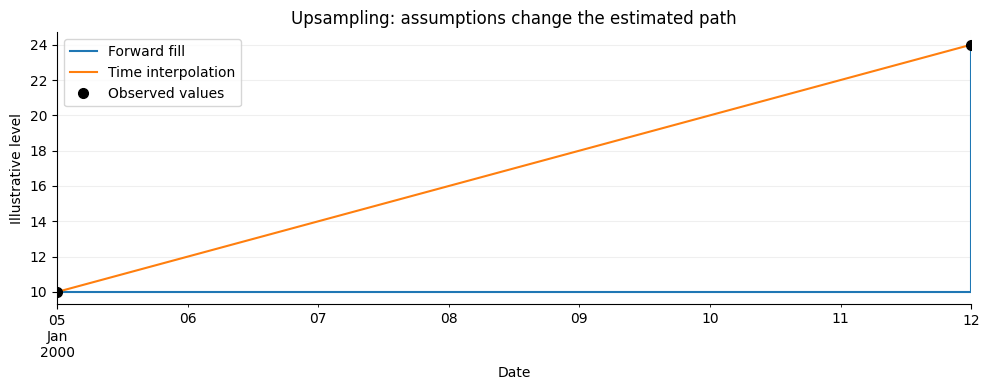

In [ ]:
weekly_levels = pd.Series([10.0, 24.0], index=pd.to_datetime(["2000-01-05", "2000-01-12"]), name="level")
daily_grid = weekly_levels.resample("D").asfreq()
upsampled = pd.DataFrame({
    "observed_only": daily_grid,
    "forward_fill": weekly_levels.resample("D").ffill(),
    "forward_fill_limit_2": weekly_levels.resample("D").ffill(limit=2),
    "time_interpolation": daily_grid.interpolate(method="time", limit_area="inside"),
})
display(upsampled)
display(weekly_levels.resample("W-THU").ffill().rename("Thursday_grid"))

fig, ax = plt.subplots()
upsampled["forward_fill"].plot(ax=ax, drawstyle="steps-post", label="Forward fill")
upsampled["time_interpolation"].plot(ax=ax, label="Time interpolation")
weekly_levels.plot(ax=ax, style="o", color="black", label="Observed values", markersize=7)
ax.set(title="Upsampling: assumptions change the estimated path", xlabel="Date", ylabel="Illustrative level")
ax.legend()
plt.tight_layout()
plt.show()


### Period-Indexed Data

To make boundaries explicit, convert monthly periods to month-start timestamps,
aggregate annually, and then convert back to annual periods.
Placing annual values at the beginning or end of a year produces different
upsampling results. Repeating an annual value across quarters does not create
new observations.


In [ ]:
period_frame = pd.DataFrame(
    np.random.default_rng(21).normal(size=(24, 4)),
    index=pd.period_range("2000-01", "2001-12", freq="M"),
    columns=["Colorado", "Texas", "New York", "Ohio"],
)
annual_frame = period_frame.to_timestamp(how="start").resample("YE-DEC").mean().to_period("Y-DEC")
display(annual_frame)

quarter_grid = pd.period_range("2000Q1", "2001Q4", freq="Q-DEC")
annual_at_start = annual_frame.copy()
annual_at_start.index = annual_frame.index.asfreq("Q-DEC", how="start")
annual_at_end = annual_frame.copy()
annual_at_end.index = annual_frame.index.asfreq("Q-DEC", how="end")
display(annual_at_start.reindex(quarter_grid).ffill().add_suffix("_start_anchored"))
display(annual_at_end.reindex(quarter_grid).ffill().add_suffix("_end_anchored"))

# Different fiscal-quarter labels can be obtained explicitly.
display(period_frame.index.asfreq("Q-MAR")[:6])


,Colorado,Texas,New York,Ohio
2000,-0.112432,0.316478,-0.218411,0.350082
2001,0.242698,-0.148659,0.046598,-0.002507


,Colorado_start_anchored,Texas_start_anchored,New York_start_anchored,Ohio_start_anchored
2000Q1,-0.112432,0.316478,-0.218411,0.350082
2000Q2,-0.112432,0.316478,-0.218411,0.350082
2000Q3,-0.112432,0.316478,-0.218411,0.350082
2000Q4,-0.112432,0.316478,-0.218411,0.350082
2001Q1,0.242698,-0.148659,0.046598,-0.002507
2001Q2,0.242698,-0.148659,0.046598,-0.002507
2001Q3,0.242698,-0.148659,0.046598,-0.002507
2001Q4,0.242698,-0.148659,0.046598,-0.002507


,Colorado_end_anchored,Texas_end_anchored,New York_end_anchored,Ohio_end_anchored
2000Q1,NaN,NaN,NaN,NaN
2000Q2,NaN,NaN,NaN,NaN
2000Q3,NaN,NaN,NaN,NaN
2000Q4,-0.112432,0.316478,-0.218411,0.350082
2001Q1,-0.112432,0.316478,-0.218411,0.350082
2001Q2,-0.112432,0.316478,-0.218411,0.350082
2001Q3,-0.112432,0.316478,-0.218411,0.350082
2001Q4,0.242698,-0.148659,0.046598,-0.002507


PeriodIndex(['2000Q4', '2000Q4', '2000Q4', '2001Q1', '2001Q1', '2001Q1'], dtype='period[Q-MAR]')

<a id="windows"></a>
## 9. Rolling and Expanding Windows

The following cell generates **synthetic price paths** with a fixed random seed.
Column names `AAPL`, `MSFT`, `XOM`, and `SPX` follow the original course examples,
but the numbers are not actual prices or returns for these assets.
The data are generated on a business-day grid, so no initial forward filling is needed.
In real data, filling missing prices can create artificial zero returns.

`rolling(60)` uses the most recent 60 observations; `rolling("20D")` uses the
most recent 20 calendar days. Business days are not necessarily exchange trading
days; this example does not incorporate an exchange holiday calendar.


In [ ]:
price_rng = np.random.default_rng(30)
price_dates = pd.date_range("2005-01-03", "2011-12-30", freq="B")
market_log_returns = price_rng.normal(0.0002, 0.009, len(price_dates))
simulated_log_returns = np.column_stack([
    1.2 * market_log_returns + price_rng.normal(0.0001, 0.012, len(price_dates)),
    0.9 * market_log_returns + price_rng.normal(0.0001, 0.008, len(price_dates)),
    0.7 * market_log_returns + price_rng.normal(0.0001, 0.010, len(price_dates)),
    market_log_returns,
])
simulated_prices = pd.DataFrame(
    100 * np.exp(simulated_log_returns.cumsum(axis=0)),
    index=price_dates, columns=["AAPL", "MSFT", "XOM", "SPX"],
)
close_prices = simulated_prices[["AAPL", "MSFT", "XOM"]]
display(simulated_prices.head())


,AAPL,MSFT,XOM,SPX
2005-01-03,101.559574,102.135156,101.234914,101.447554
2005-01-04,103.429647,103.315593,101.846446,102.148895
2005-01-05,102.469838,102.445440,102.631796,101.281372
2005-01-06,102.294808,100.514240,102.216042,101.108527
2005-01-07,101.163164,99.606788,102.583547,100.868118


### Rolling Mean, Standard Deviation, and Expanding Mean

`min_periods` sets the minimum number of nonmissing observations needed for a result.
An expanding window accumulates observations from the start, while a rolling window
drops older observations as it advances. Price standard deviation measures dispersion
in price levels; use the standard deviation of **returns** to analyze return volatility.


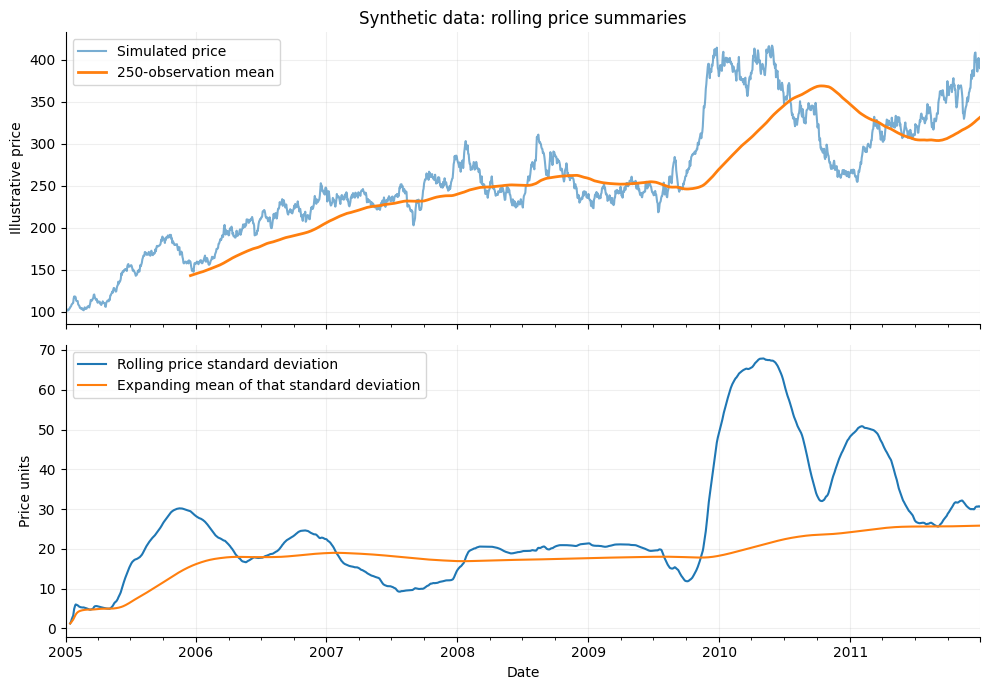

In [ ]:
apple_prices = close_prices["AAPL"]
rolling_mean_250 = apple_prices.rolling(250, min_periods=250).mean()
rolling_price_std = apple_prices.rolling(250, min_periods=10).std()
expanding_price_std_mean = rolling_price_std.expanding(min_periods=1).mean()

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
apple_prices.plot(ax=axes[0], alpha=0.6, label="Simulated price")
rolling_mean_250.plot(ax=axes[0], linewidth=2, label="250-observation mean")
axes[0].set(title="Synthetic data: rolling price summaries", ylabel="Illustrative price")
axes[0].legend()
rolling_price_std.plot(ax=axes[1], label="Rolling price standard deviation")
expanding_price_std_mean.plot(ax=axes[1], label="Expanding mean of that standard deviation")
axes[1].set(xlabel="Date", ylabel="Price units")
axes[1].legend()
plt.tight_layout()
plt.show()


,60_observations,20_calendar_days
2005-01-25,105.436880,106.069135
2005-01-26,106.136614,107.193227
2005-01-27,106.694806,108.306021
2005-01-28,107.254514,108.944884
2005-01-31,107.715657,110.534722


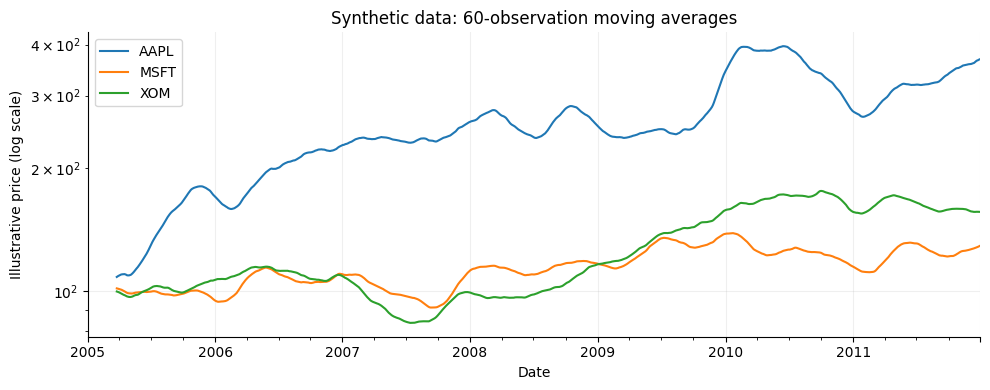

In [ ]:
window_comparison = pd.DataFrame({
    "60_observations": apple_prices.rolling(60, min_periods=1).mean(),
    "20_calendar_days": apple_prices.rolling("20D", min_periods=1).mean(),
})
display(window_comparison.loc["2005-01"].tail())

ax = close_prices.rolling(60, min_periods=60).mean().plot(logy=True)
ax.set(title="Synthetic data: 60-observation moving averages", xlabel="Date", ylabel="Illustrative price (log scale)")
plt.tight_layout()
plt.show()


### Exponentially Weighted Mean

A simple moving average gives equal weight to observations within its window.
An exponentially weighted mean gives more weight to recent observations.
`span=30` corresponds to `alpha=2/(30+1)`; it does not restrict the calculation to
30 rows. `adjust=False` uses a recursive calculation, while `min_periods`
controls when results first appear.


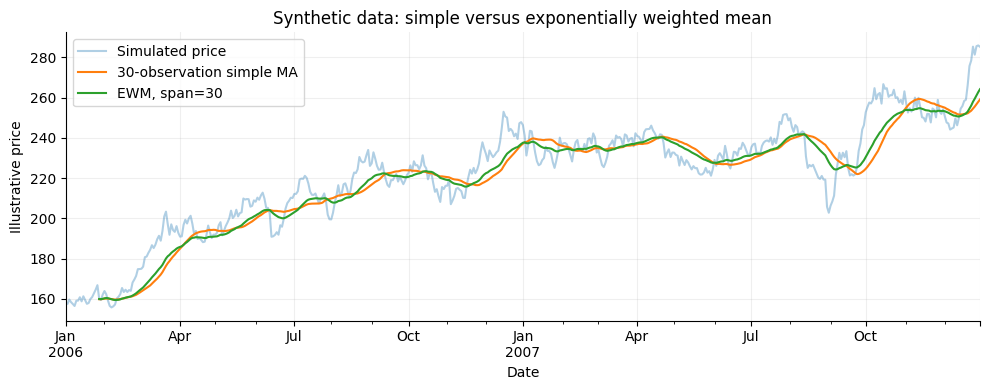

In [ ]:
sample_prices = apple_prices.loc["2006":"2007"]
sma_30 = sample_prices.rolling(30, min_periods=20).mean()
ewm_30 = sample_prices.ewm(span=30, adjust=False, min_periods=20).mean()

fig, ax = plt.subplots()
sample_prices.plot(ax=ax, alpha=0.35, label="Simulated price")
sma_30.plot(ax=ax, label="30-observation simple MA")
ewm_30.plot(ax=ax, label="EWM, span=30")
ax.set(title="Synthetic data: simple versus exponentially weighted mean", xlabel="Date", ylabel="Illustrative price")
ax.legend()
plt.tight_layout()
plt.show()


### Rolling Correlation

`pct_change(fill_method=None)` produces fractional returns: 0.02 represents 2%.
It does not silently fill missing prices. Compute correlations from observations
aligned on the same dates. Correlation between price levels differs from correlation
between returns, and neither establishes causation.


,AAPL,MSFT,XOM
2005-05-23,0.634035,0.796479,0.571946
2005-05-24,0.631942,0.783515,0.570581
2005-05-25,0.618098,0.783178,0.562701
2005-05-26,0.620384,0.771934,0.581747
2005-05-27,0.620554,0.770844,0.581616


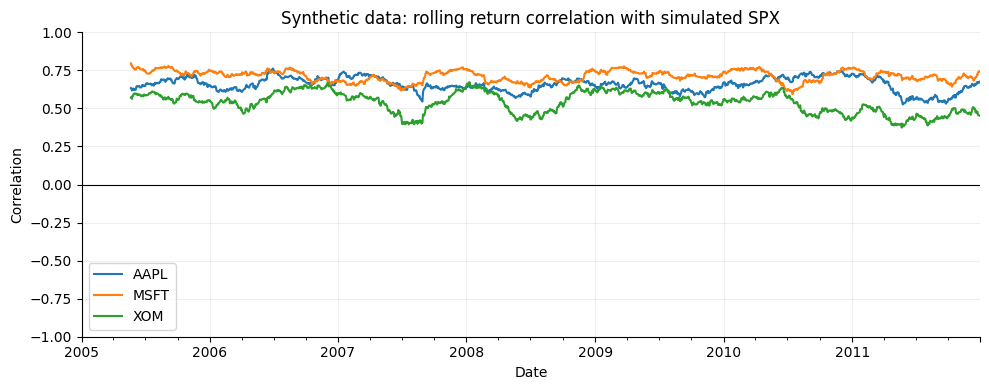

In [ ]:
asset_returns = close_prices.pct_change(fill_method=None)
market_returns = simulated_prices["SPX"].pct_change(fill_method=None)
rolling_corr = asset_returns.rolling(125, min_periods=100).corr(market_returns)
display(rolling_corr.dropna().head())

ax = rolling_corr.plot()
ax.set(title="Synthetic data: rolling return correlation with simulated SPX", xlabel="Date", ylabel="Correlation", ylim=(-1, 1))
ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()


### User-Defined Windows

The original notebook used `percentileofscore` to locate a 2% return within a window's
distribution. Here, the **weak percentile** is the percentage of observations less
than or equal to the threshold. This differs from the default rank definition,
particularly when observations equal the threshold. A NumPy implementation avoids
an additional dependency. With `raw=True`, `.apply()` passes an array to the function.


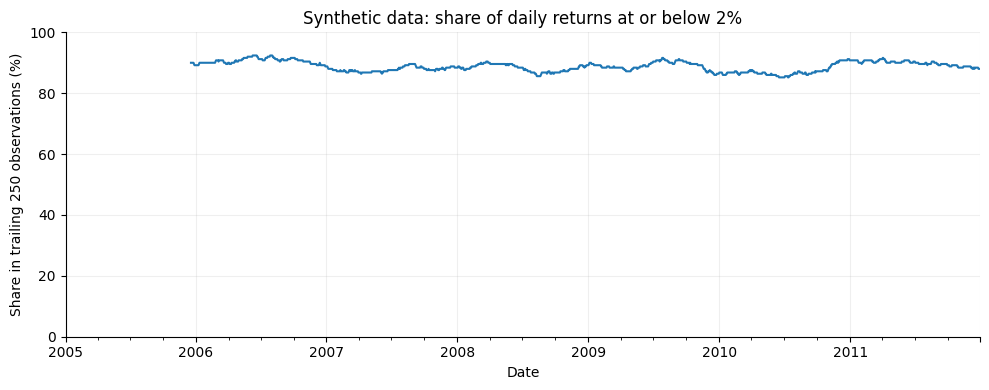

In [ ]:
def share_at_or_below_two_percent(values):
    """Percentage of window observations whose decimal return is <= 0.02."""
    finite_values = values[np.isfinite(values)]
    if finite_values.size == 0:
        return np.nan
    return 100.0 * np.mean(finite_values <= 0.02)

rolling_percentile = asset_returns["AAPL"].rolling(250, min_periods=250).apply(
    share_at_or_below_two_percent, raw=True
)
ax = rolling_percentile.plot()
ax.set(title="Synthetic data: share of daily returns at or below 2%", xlabel="Date", ylabel="Share in trailing 250 observations (%)", ylim=(0, 100))
plt.tight_layout()
plt.show()


<a id="workflow"></a>
## 10. A Complete Workflow

**Question:** How can service records with invalid dates, duplicate IDs, and
unobserved dates be converted into daily event counts?

The records below are synthetic. Assume that timestamps use New York local time,
`event_id` uniquely identifies an event, and repeated IDs represent duplicate exports.
Records with invalid or missing timestamps are retained separately for review.

Assume also that the export completely covers **October 1–5, 2026**. Under this
assumption, dates without records can be assigned zero events. An incomplete export
would require retaining uncertainty rather than assuming that no events occurred.


In [ ]:
service_records = pd.DataFrame({
    "event_id": ["E01", "E02", "E02", "E03", "E04", "E05", "E06"],
    "timestamp": ["2026-10-01 09:00", "2026-10-01 11:30", "2026-10-01 11:30",
                  "2026-10-03 14:00", "2026-10-05 10:00", "bad-date", None],
})
clean_records = service_records.copy()
clean_records["local_time"] = pd.to_datetime(
    clean_records["timestamp"], format="%Y-%m-%d %H:%M", errors="coerce"
)
rejected_records = clean_records.loc[clean_records["local_time"].isna()].copy()
duplicate_records = clean_records.loc[
    clean_records["local_time"].notna() & clean_records.duplicated("event_id", keep="first")
].copy()
valid_records = clean_records.dropna(subset=["local_time"]).drop_duplicates("event_id").copy()
valid_records["local_time"] = valid_records["local_time"].dt.tz_localize(
    "America/New_York", ambiguous="raise", nonexistent="raise"
)
valid_records = valid_records.set_index("local_time").sort_index()

coverage_dates = pd.date_range("2026-10-01", "2026-10-05", freq="D", tz="America/New_York")
daily_counts = valid_records.resample("D").size().reindex(coverage_dates, fill_value=0).rename("events")
daily_report = daily_counts.to_frame()
daily_report["mean_over_last_3_calendar_days"] = daily_counts.rolling("3D", min_periods=1).mean()
daily_report["previous_day"] = daily_counts.shift(1)

display(rejected_records)
display(duplicate_records)
display(daily_report)


,event_id,timestamp,local_time
5,E05,bad-date,NaT
6,E06,None,NaT


,event_id,timestamp,local_time
2,E02,2026-10-01 11:30,2026-10-01 11:30:00


,events,mean_over_last_3_calendar_days,previous_day
2026-10-01 00:00:00-04:00,2,2.000000,NaN
2026-10-02 00:00:00-04:00,0,1.000000,2.0
2026-10-03 00:00:00-04:00,1,1.000000,0.0
2026-10-04 00:00:00-04:00,0,0.333333,1.0
2026-10-05 00:00:00-04:00,1,0.666667,0.0


### Sanity Checks

Check the meaning of the results as well as successful execution: identify invalid
dates, verify that resampling preserves totals, confirm that time zone conversion
preserves instants, and reconcile the original records with the cleaning outcomes.


In [ ]:
assert date_audit["parse_failed"].sum() == 2
assert date_audit["missing_input"].sum() == 1
assert minute_series.resample("5min", closed="left", label="left").sum().iloc[0] == 10
assert minute_series.resample("5min", closed="right", label="right").sum().iloc[1] == 15
assert minute_series.resample("5min").sum().sum() == minute_series.sum()
assert np.array_equal(local_index.asi8, utc_index.asi8)
assert (after_24h - before_dst).total_seconds() == 24 * 3600
assert (next_calendar_day - before_dst).total_seconds() == 23 * 3600
assert len(service_records) == len(rejected_records) + len(duplicate_records) + len(valid_records)
assert valid_records.index.is_monotonic_increasing
assert valid_records["event_id"].is_unique
assert daily_counts.tolist() == [2, 0, 1, 0, 1]
assert daily_counts.sum() == len(valid_records)
assert rolling_corr.abs().max().max() <= 1 + 1e-12
assert rolling_percentile.dropna().between(0, 100).all()
print("All 15 semantic checks passed.")


All 15 semantic checks passed.


<a id="practice"></a>
## 11. Practice and Solutions

Try the five exercises before opening the reference solutions. No additional files are required.

1. Parse `['31/01/2026', '15/02/2026', '31/02/2026']` using day/month/year format and flag the invalid date.
2. Generate the third Friday of every month in 2026 and verify that all dates are Fridays.
3. Interpret `2026-11-02 09:00` as New York local time and convert it to Shanghai time.
4. Sum the workflow's daily counts into Monday–Sunday weeks labeled on Sunday. Explain why a partially observed week should not be compared directly with a complete week.
5. Construct a prediction for each day's service count using the preceding three days, excluding the current day.

<details>
<summary>Reference solutions</summary>

```python
# 1. Explicit day-first format; invalid February date becomes NaT.
answer_1 = pd.to_datetime(
    ['31/01/2026', '15/02/2026', '31/02/2026'],
    format='%d/%m/%Y', errors='coerce'
)
assert answer_1.isna().tolist() == [False, False, True]

# 2. Third Friday each month.
answer_2 = pd.date_range('2026-01-01', '2026-12-31', freq='WOM-3FRI')
assert len(answer_2) == 12 and (answer_2.dayofweek == 4).all()

# 3. New York is on standard time on this date: Shanghai is 13 hours ahead.
answer_3 = pd.Timestamp('2026-11-02 09:00').tz_localize('America/New_York').tz_convert('Asia/Shanghai')
assert answer_3.hour == 22

# 4. Right-closed weekly bins ending Sunday; flag the observed coverage.
answer_4 = daily_counts.resample('W-SUN', closed='right', label='right').sum()
coverage_days_per_week = daily_counts.resample('W-SUN', closed='right', label='right').size()
# Only 4 and 1 covered days in the two bins: neither is a full observed week.

# 5. For this complete daily grid, shifting first excludes the current day.
answer_5 = daily_counts.shift(1).rolling(3, min_periods=3).mean()
assert np.isclose(answer_5.iloc[3], 1.0)
```

Exercise 5 uses a complete daily grid. Its first three results are missing because
there is insufficient prior history. For irregular data, three observations do not
necessarily represent three calendar days; define a regular grid or use a time-based window.

</details>


<a id="reference"></a>
## 12. Quick Reference

| Task | Method | Key consideration |
|---|---|---|
| Parse a known date format | `pd.to_datetime(s, format=..., errors='coerce')` | Audit parsing failures separately |
| Format a date as text | `stamp.strftime(...)` / `s.dt.strftime(...)` | The output becomes a string |
| Slice by date label | `s.loc['2026-01':'2026-03']` | Sort first; endpoints are generally included |
| Select by position | `s.iloc[::2]` | Row positions, not elapsed time |
| Generate a time grid | `pd.date_range(..., freq='D')` | Distinguish business days from holiday calendars |
| Create a lag | `s.shift(1)` | One row does not necessarily mean one day |
| Shift time labels | `s.shift(1, freq='D')` | Different from lagging values |
| Assign a time zone | `idx.tz_localize(...)` | Verify the source's local time zone |
| Convert time zones | `idx.tz_convert(...)` | The actual instants remain unchanged |
| Create monthly periods | `idx.to_period('M')` | Multiple dates may map to the same period |
| Downsample | `s.resample('ME').mean()` | Match aggregation to the variable's meaning |
| Create a new frequency grid | `s.resample('D').asfreq()` | New positions may be missing |
| Interpolate by time | `s.interpolate(method='time')` | May use future information |
| Use an observation window | `s.rolling(30).mean()` | 30 observations |
| Use an elapsed-time window | `s.rolling('30D').mean()` | 30 calendar days |
| Use an expanding window | `s.expanding().mean()` | Accumulates from the beginning |
| Apply exponential weighting | `s.ewm(span=30, adjust=False).mean()` | Weights decay into the past |

### Questions to Resolve before Analysis

What are the date format, source time zone, and unit of observation? Are duplicates
valid? Can missing dates legitimately be interpreted as zeros? Which local calendar
defines the aggregation boundaries? Does a window include current or future information?
These decisions determine whether the calculations answer the intended question.

### Further Reading

* [pandas time series / date functionality](https://pandas.pydata.org/docs/user_guide/timeseries.html)
* [pandas.to_datetime](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html)
* [pandas.DataFrame.resample](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html)
* [pandas.PeriodIndex.from_fields](https://pandas.pydata.org/docs/reference/api/pandas.PeriodIndex.from_fields.html)
* [Python datetime and format codes](https://docs.python.org/3/library/datetime.html)
* [Python zoneinfo](https://docs.python.org/3/library/zoneinfo.html)
* [dateutil parser](https://dateutil.readthedocs.io/en/stable/parser.html)

**Validation:** The saved outputs identify the tested environment. Compatibility
with every Python or pandas version has not been tested. All simulated datasets
and their charts are provided solely to demonstrate the methods.
